# An Intelligent Machine Learning System for Electric Vehicle Battery Health Assessment and Remaining Useful Life Prediction

**CSC61304 Machine Learning and Intelligent Systems | Individual Assignment**
Prajin Sapkota | Student ID 0382319

**Dataset:** MIT-Stanford-Toyota fast-charging battery dataset, 3 batch files
(Severson et al., 2019, *Nature Energy* 4, 383-391). Download: https://data.matr.io/1/projects/5c48dd2bc625d700019f3204

**Experiments**
1. **SOH regression**: predict State of Health (discharge capacity / 1.1 Ah nominal) from cycle measurements, with no capacity-based inputs.
2. **RUL regression**: predict Remaining Useful Life (cycles until 80% capacity) from cycle history.

**Models:** Linear Regression (baseline), Random Forest, XGBoost, Support Vector Regression. **Metrics:** MAE, RMSE, R2. **Explainability:** SHAP.

All train/test splits are done **by battery cell**, so no cell appears in both sets.
The raw .mat files are loaded from `./data/raw` and are not included with this notebook.

## 0. Setup

In [ ]:
import glob, os, time
from pathlib import Path
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# If a package is missing, run once in a terminal:
#   pip install h5py pandas numpy scikit-learn xgboost shap pyarrow matplotlib seaborn

SEED = 42
np.random.seed(SEED)
OUT_DIR = Path('./figures')
OUT_DIR.mkdir(exist_ok=True)
pd.set_option('display.width', 140)

## 1. Locate the data files

In [ ]:
DATA_DIR = './data/raw'      # folder containing the three .mat files (relative to this notebook)
files = sorted(glob.glob(DATA_DIR + '/*batchdata*.mat'))
main_files = [f for f in files if any(t in f for t in ['2017-05-12', '2017-06-30', '2018-04-12'])]
for f in main_files:
    print(f)
assert len(main_files) == 3, 'Expected 3 batch files - check DATA_DIR'

## 2. Load per-cycle summaries and cycle-life labels from the .mat files

In [ ]:
KEYS = ['cycle', 'QDischarge', 'QCharge', 'IR', 'Tmax', 'Tmin', 'Tavg', 'chargetime']

def load_batch(path):
    tag = os.path.basename(path)[:10]
    frames = []
    with h5py.File(path, 'r') as f:
        batch = f['batch']
        n = batch['summary'].shape[0]
        for i in range(n):
            s = f[batch['summary'][i, 0]]
            d = {k: np.array(s[k]).ravel() for k in KEYS}
            m = min(len(v) for v in d.values())
            frame = pd.DataFrame({k: v[:m] for k, v in d.items()})
            frame.insert(0, 'cell_id', f'{tag}_c{i}')
            frames.append(frame)
    return pd.concat(frames, ignore_index=True)

def read_cycle_life(path):
    tag = os.path.basename(path)[:10]
    out = {}
    with h5py.File(path, 'r') as f:
        b = f['batch']
        for i in range(b['cycle_life'].shape[0]):
            out[f'{tag}_c{i}'] = float(np.array(f[b['cycle_life'][i, 0]]).ravel()[0])
    return out

raw = pd.concat([load_batch(p) for p in main_files], ignore_index=True)
cl = {}
for p in main_files:
    cl.update(read_cycle_life(p))
print(raw.shape, raw['cell_id'].nunique(), 'cells')
raw.head()

## 3. Cleaning and target definition
- Remove sensor glitches, including the all-zero first cycle and implausible charge times.
- Drop cells with no cycle-life label.
- Drop cells whose test stopped before reaching 80% capacity (the label is then not a true end of life).
- **SOH** = discharge capacity / 1.1 Ah (nominal). **RUL** = EOL cycle - current cycle.

First, inspect the charge-time column, which contains a few extreme values.

In [4]:
ct = raw.loc[raw['chargetime'] > 0, 'chargetime']
print(ct.describe(percentiles=[.5, .99, .999]).round(2))
too_long = raw['chargetime'] > 25
print(too_long.sum(), 'rows above 25 min, in', raw.loc[too_long, 'cell_id'].nunique(), 'cells')

count    114692.00
mean         11.15
std           6.16
min           8.90
50%          10.64
99%          20.00
99.9%        23.73
max        1290.37
Name: chargetime, dtype: float64
90 rows above 25 min, in 52 cells


In [5]:
NOMINAL = 1.1
CHARGETIME_MAX = 25      # minutes; rows above this are treated as sensor glitches (see the printout above)

df = raw.copy()
df['label'] = df['cell_id'].map(cl)
n_cells_raw, n_rows_raw = df['cell_id'].nunique(), len(df)

# 1) sensor glitches
ok = (df['QDischarge'].between(0.5, 1.3) & (df['IR'] > 0)
      & (df['chargetime'] > 0) & (df['chargetime'] <= CHARGETIME_MAX))
print('glitch rows removed:', (~ok).sum())
df = df[ok]

# 2) missing label
no_label = sorted(set(raw['cell_id']) - set(df.dropna(subset=['label'])['cell_id']))
df = df.dropna(subset=['label'])

# 3) tests stopped before 80% capacity
def q_at_eol(g):
    g = g.sort_values('cycle')
    return g[g['cycle'] <= g['label'].iloc[0]]['QDischarge'].tail(5).median()

q_eol = pd.Series({cid: q_at_eol(g) for cid, g in df.groupby('cell_id')})
censored = sorted(q_eol[q_eol > 0.90].index)
df = df[df['cell_id'].isin(q_eol[q_eol <= 0.90].index)].copy()

# 4) targets
df['EOL_cycle'] = df['label']
df['RUL'] = df['EOL_cycle'] - df['cycle']
df['SOH'] = df['QDischarge'] / NOMINAL
df = df[df['RUL'] >= 0].reset_index(drop=True)

print('no label:', no_label)
print('stopped before EOL:', censored)
print('cells kept:', df['cell_id'].nunique(), 'of', n_cells_raw)
print('rows kept:', len(df), 'of', n_rows_raw)
print(df.groupby('cell_id')['EOL_cycle'].first().describe())
print(df.groupby('cell_id')['SOH'].min().describe())      # should be about 0.80
df.to_parquet('./battery_summary.parquet')

glitch rows removed: 160
no label: ['2018-04-12_c23', '2018-04-12_c32']
stopped before EOL: ['2017-05-12_c0', '2017-05-12_c1', '2017-05-12_c10', '2017-05-12_c12', '2017-05-12_c13', '2017-05-12_c2', '2017-05-12_c22', '2017-05-12_c3', '2017-05-12_c4', '2017-05-12_c8']
cells kept: 128 of 140
rows kept: 98549 of 114738
count     128.000000
mean      771.515625
std       323.455555
min       148.000000
25%       497.250000
50%       731.000000
75%       946.500000
max      1935.000000
Name: EOL_cycle, dtype: float64
count    128.000000
mean       0.800752
std        0.001391
min        0.794725
25%        0.800118
50%        0.800483
75%        0.800957
max        0.807634
Name: SOH, dtype: float64


## 4. Feature engineering
Experiment 1 (SOH) uses **12 features and no capacity-based inputs**, otherwise the model would simply recompute the target.
Experiment 2 (RUL) adds 3 capacity-trend features (**15 total**).
Rolling features look backwards only. The early-life reference (each cell's first 5 recorded cycles) is a minor exception, since cycles 2-5 are compared with a reference that includes slightly later cycles.

In [6]:
df = pd.read_parquet('./battery_summary.parquet')
df = df.sort_values(['cell_id', 'cycle']).reset_index(drop=True)

def make_features(g):
    g = g.copy()
    g['Trange'] = g['Tmax'] - g['Tmin']
    for c in ['IR', 'Tavg', 'chargetime', 'QDischarge']:
        g[c + '_ma5'] = g[c].rolling(5, min_periods=1).mean()
    for c in ['IR', 'chargetime', 'QDischarge']:
        g[c + '_slope10'] = ((g[c] - g[c].shift(10)) / 10).fillna(0)
    ref = g.iloc[:5]
    g['IR_rel'] = g['IR'] / ref['IR'].mean()
    g['chargetime_rel'] = g['chargetime'] / ref['chargetime'].mean()
    g['QD_drop'] = ref['QDischarge'].mean() - g['QDischarge_ma5']
    return g

df = pd.concat([make_features(g) for _, g in df.groupby('cell_id')], ignore_index=True)

FEATS_SOH = ['cycle', 'IR', 'Tavg', 'chargetime', 'Trange',
             'IR_ma5', 'Tavg_ma5', 'chargetime_ma5',
             'IR_slope10', 'chargetime_slope10', 'IR_rel', 'chargetime_rel']          # 12
FEATS_RUL = FEATS_SOH + ['QDischarge_ma5', 'QDischarge_slope10', 'QD_drop']          # 15
print(len(FEATS_SOH), len(FEATS_RUL), df.shape)
df[FEATS_RUL + ['SOH', 'RUL']].describe().T.round(3)

12 15 (98549, 24)


,count,mean,std,min,25%,50%,75%,max
cycle,98549.0,453.307,336.308,1.000,194.000,390.000,645.000,1934.000
IR,98549.0,0.016,0.001,0.010,0.016,0.016,0.017,0.024
Tavg,98549.0,34.367,1.868,25.732,33.080,34.126,35.673,41.440
chargetime,98549.0,10.865,1.351,8.897,10.046,10.257,11.096,24.938
Trange,98549.0,6.679,2.018,0.161,5.712,6.897,8.005,13.766
IR_ma5,98549.0,0.016,0.001,0.013,0.016,0.016,0.017,0.023
Tavg_ma5,98549.0,34.364,1.858,26.007,33.077,34.116,35.663,41.307
chargetime_ma5,98549.0,10.841,1.249,8.897,10.046,10.248,11.102,23.311
IR_slope10,98549.0,0.000,0.000,-0.000,-0.000,0.000,0.000,0.000
chargetime_slope10,98549.0,0.009,0.053,-0.782,-0.000,0.000,0.005,0.940


## 5. Exploratory plots

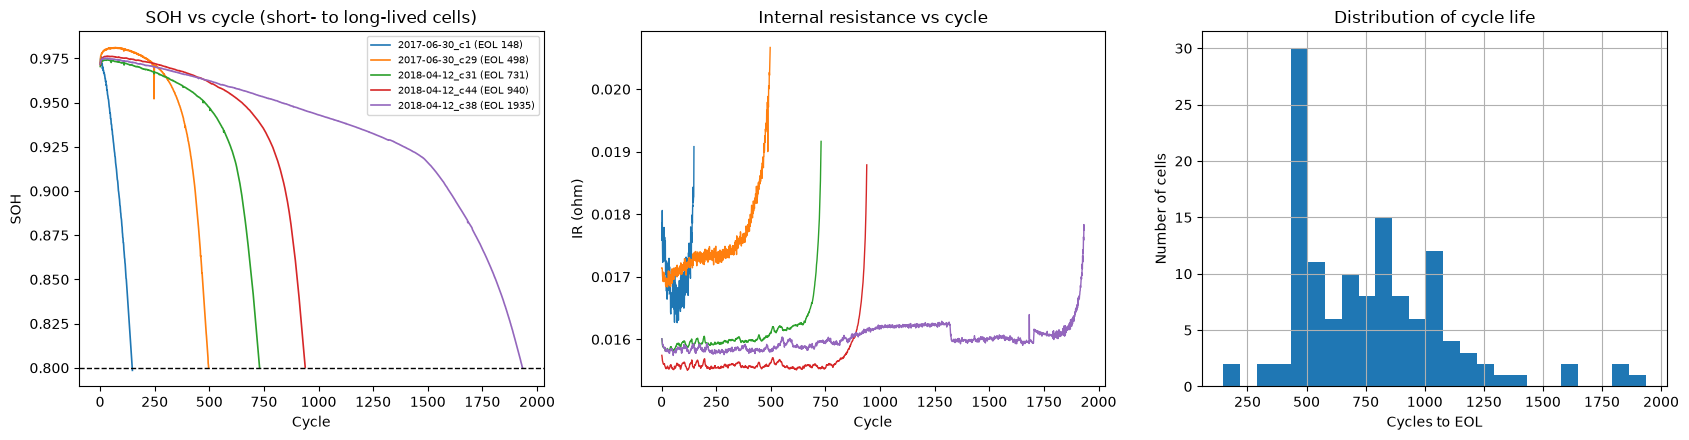

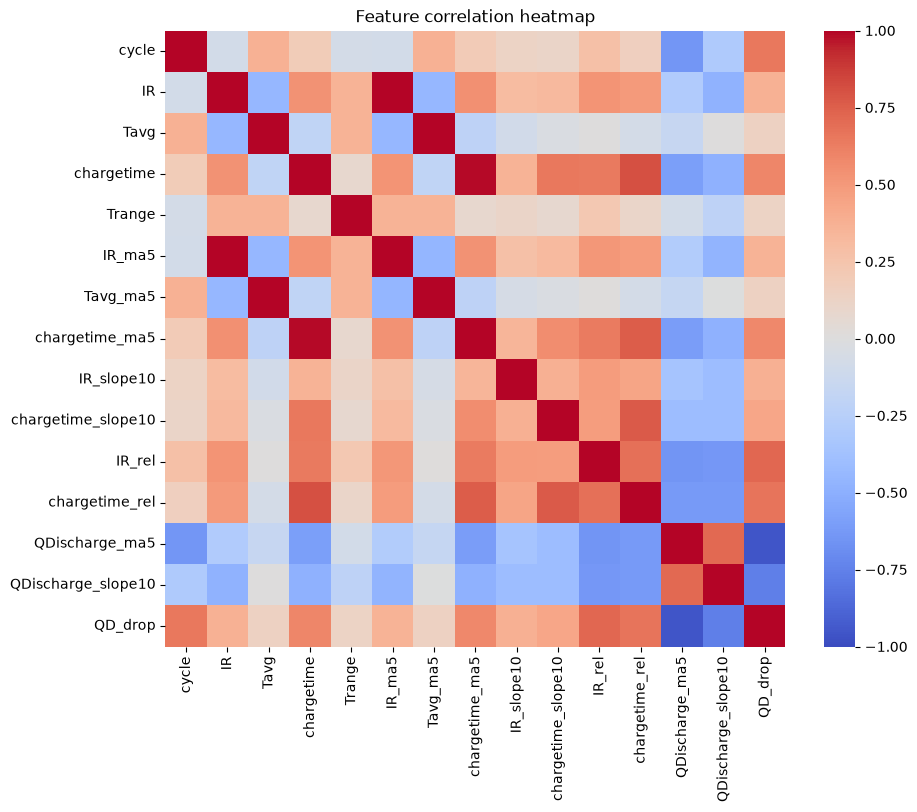

In [7]:
eol = df.groupby('cell_id')['EOL_cycle'].first().sort_values()
picks = eol.index[[int(round(q * (len(eol) - 1))) for q in [0, .25, .5, .75, 1]]]

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for cid in picks:
    s = df[df['cell_id'] == cid]
    ax[0].plot(s['cycle'], s['SOH'], lw=1.2, label=f'{cid} (EOL {int(eol[cid])})')
    ax[1].plot(s['cycle'], s['IR'], lw=1)
ax[0].axhline(0.80, color='k', ls='--', lw=1)
ax[0].set(title='SOH vs cycle (short- to long-lived cells)', xlabel='Cycle', ylabel='SOH')
ax[0].legend(fontsize=7)
ax[1].set(title='Internal resistance vs cycle', xlabel='Cycle', ylabel='IR (ohm)')
eol.hist(bins=25, ax=ax[2])
ax[2].set(title='Distribution of cycle life', xlabel='Cycles to EOL', ylabel='Number of cells')
plt.tight_layout()
plt.savefig(OUT_DIR / 'eda_overview.png', dpi=200, bbox_inches='tight')
plt.show()

plt.figure(figsize=(10, 8))
sns.heatmap(df[FEATS_RUL].corr(), cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Feature correlation heatmap')
plt.savefig(OUT_DIR / 'eda_correlation.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Train/test split by cell, and the four models

In [8]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.base import clone
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
tr_idx, te_idx = next(gss.split(df, groups=df['cell_id']))
train, test = df.iloc[tr_idx], df.iloc[te_idx]
print('train cells:', train['cell_id'].nunique(), '| test cells:', test['cell_id'].nunique())
print('train rows:', len(train), '| test rows:', len(test))
assert set(train['cell_id']).isdisjoint(test['cell_id'])   # no cell in both sets

models = {
    'Linear Regression': make_pipeline(StandardScaler(), LinearRegression()),
    'Random Forest': RandomForestRegressor(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=SEED),
    'XGBoost': XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                            subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=SEED),
    'SVR': TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.05, gamma='scale')),
        transformer=StandardScaler()),
}

def fit_predict(proto, name, X_tr, y_tr, X_te, svr_rows=15000):
    m = clone(proto)
    if name == 'SVR':   # SVR is slow on tens of thousands of rows, so train on a random subsample
        idx = X_tr.sample(min(svr_rows, len(X_tr)), random_state=SEED).index
        m.fit(X_tr.loc[idx], y_tr.loc[idx])
    else:
        m.fit(X_tr, y_tr)
    return m, m.predict(X_te)

def scores(y_true, y_pred):
    return {'MAE': mean_absolute_error(y_true, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
            'R2': r2_score(y_true, y_pred)}

def run(target, feats):
    rows, fitted = [], {}
    for name, proto in models.items():
        t0 = time.time()
        m, p = fit_predict(proto, name, train[feats], train[target], test[feats])
        rows.append({'Model': name, **scores(test[target], p)})
        fitted[name] = m
        print(f'done: {name} ({time.time() - t0:.0f}s)')
    return pd.DataFrame(rows).round(4), fitted

train cells: 102 | test cells: 26
train rows: 77829 | test rows: 20720


## 7. Experiment 1: SOH prediction

In [9]:
res_soh, fit_soh = run('SOH', FEATS_SOH)
res_soh

done: Linear Regression (0s)
done: Random Forest (139s)
done: XGBoost (80s)
done: SVR (120s)


,Model,MAE,RMSE,R2
0,Linear Regression,0.0196,0.0251,0.6991
1,Random Forest,0.0170,0.0268,0.6576
2,XGBoost,0.0155,0.0238,0.7312
3,SVR,0.0152,0.0206,0.7985


## 8. Experiment 2: RUL prediction (with capacity-trend features)

In [10]:
res_rul, fit_rul = run('RUL', FEATS_RUL)
res_rul

done: Linear Regression (0s)
done: Random Forest (155s)
done: XGBoost (8s)
done: SVR (57s)


,Model,MAE,RMSE,R2
0,Linear Regression,157.4855,209.1213,0.6486
1,Random Forest,76.3700,117.0401,0.8899
2,XGBoost,78.0645,121.5768,0.8812
3,SVR,111.5402,158.0944,0.7992


## 9. Ablation: RUL without capacity-trend features

In [11]:
res_rul_nocap, fit_rul_nocap = run('RUL', FEATS_SOH)
res_rul_nocap

done: Linear Regression (0s)
done: Random Forest (154s)
done: XGBoost (6s)
done: SVR (66s)


,Model,MAE,RMSE,R2
0,Linear Regression,177.3305,239.9196,0.5375
1,Random Forest,116.6250,169.9089,0.7680
2,XGBoost,119.2303,170.0412,0.7677
3,SVR,184.4537,272.9591,0.4013


## 10. Hyperparameter tuning (XGBoost)
Randomised search with 3-fold CV **grouped by cell**, using the training cells only. Only XGBoost is tuned (a limitation: the other models use default settings).

In [12]:
from sklearn.model_selection import GroupKFold, RandomizedSearchCV

param_dist = {
    'n_estimators': [200, 400, 600],
    'learning_rate': [0.03, 0.05, 0.10],
    'max_depth': [4, 6, 8],
    'subsample': [0.7, 0.8, 0.9],
    'colsample_bytree': [0.7, 0.8, 0.9],
    'min_child_weight': [1, 3, 5],
}
search = RandomizedSearchCV(
    XGBRegressor(objective='reg:squarederror', n_jobs=1, random_state=SEED),
    param_distributions=param_dist, n_iter=12,
    scoring='neg_mean_absolute_error', cv=GroupKFold(n_splits=3),
    random_state=SEED, n_jobs=-1, verbose=1)
search.fit(train[FEATS_RUL], train['RUL'], groups=train['cell_id'])
print('Best params:', search.best_params_)

tuned = search.best_estimator_
p_tuned = tuned.predict(test[FEATS_RUL])
res_rul_tuned = pd.concat(
    [res_rul, pd.DataFrame([{'Model': 'XGBoost (tuned)', **scores(test['RUL'], p_tuned)}])],
    ignore_index=True).round(4)
fit_rul_all = {**fit_rul, 'XGBoost (tuned)': tuned}
res_rul_tuned

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best params: {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.7}


,Model,MAE,RMSE,R2
0,Linear Regression,157.4855,209.1213,0.6486
1,Random Forest,76.3700,117.0401,0.8899
2,XGBoost,78.0645,121.5768,0.8812
3,SVR,111.5402,158.0944,0.7992
4,XGBoost (tuned),75.1013,117.0354,0.8899


In [16]:
# Fair-comparison tuning: Random Forest and SVR (RUL experiment, grouped 3-fold CV on training cells)
rf_search = RandomizedSearchCV(
    RandomForestRegressor(n_jobs=1, random_state=SEED),
    {'n_estimators': [100, 200, 300], 'max_depth': [None, 12, 20],
     'min_samples_leaf': [2, 5, 10], 'max_features': [0.5, 0.7, 1.0]},
    n_iter=8, scoring='neg_mean_absolute_error', cv=GroupKFold(n_splits=3),
    random_state=SEED, n_jobs=-1, verbose=1)
rf_search.fit(train[FEATS_RUL], train['RUL'], groups=train['cell_id'])
rf_tuned = rf_search.best_estimator_
print('RF best params:', rf_search.best_params_)

sub = train.sample(15000, random_state=SEED)          # same 15k-row subsample idea as the SVR baseline
svr_search = RandomizedSearchCV(
    TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), SVR()), transformer=StandardScaler()),
    {'regressor__svr__C': [1, 10, 100], 'regressor__svr__epsilon': [0.01, 0.05, 0.1],
     'regressor__svr__gamma': ['scale', 0.05, 0.2]},
    n_iter=8, scoring='neg_mean_absolute_error', cv=GroupKFold(n_splits=3),
    random_state=SEED, n_jobs=-1, verbose=1)
svr_search.fit(sub[FEATS_RUL], sub['RUL'], groups=sub['cell_id'])
svr_tuned = svr_search.best_estimator_
print('SVR best params:', svr_search.best_params_)

extra = pd.DataFrame([
    {'Model': 'Random Forest (tuned)', **scores(test['RUL'], rf_tuned.predict(test[FEATS_RUL]))},
    {'Model': 'SVR (tuned)', **scores(test['RUL'], svr_tuned.predict(test[FEATS_RUL]))},
])
res_rul_tuned = pd.concat([res_rul_tuned, extra], ignore_index=True).round(4)
fit_rul_all.update({'Random Forest (tuned)': rf_tuned, 'SVR (tuned)': svr_tuned})
res_rul_tuned

Fitting 3 folds for each of 8 candidates, totalling 24 fits
RF best params: {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 0.7, 'max_depth': 20}
Fitting 3 folds for each of 8 candidates, totalling 24 fits
SVR best params: {'regressor__svr__gamma': 'scale', 'regressor__svr__epsilon': 0.01, 'regressor__svr__C': 1}


,Model,MAE,RMSE,R2
0,Linear Regression,157.4855,209.1213,0.6486
1,Random Forest,76.3700,117.0401,0.8899
2,XGBoost,78.0645,121.5768,0.8812
3,SVR,111.5402,158.0944,0.7992
4,XGBoost (tuned),75.1013,117.0354,0.8899
5,Random Forest (tuned),72.3911,112.0863,0.8990
6,SVR (tuned),88.1001,133.3544,0.8571


## 11. Results summary


In [17]:
summary = pd.concat([
    res_soh.assign(Experiment='SOH'),
    res_rul_tuned.assign(Experiment='RUL (with capacity trend)'),
    res_rul_nocap.assign(Experiment='RUL (no capacity trend)'),
], ignore_index=True)[['Experiment', 'Model', 'MAE', 'RMSE', 'R2']]
summary.to_csv('./results_summary.csv', index=False)
summary

,Experiment,Model,MAE,RMSE,R2
0,SOH,Linear Regression,0.0196,0.0251,0.6991
1,SOH,Random Forest,0.0170,0.0268,0.6576
2,SOH,XGBoost,0.0155,0.0238,0.7312
3,SOH,SVR,0.0152,0.0206,0.7985
4,RUL (with capacity trend),Linear Regression,157.4855,209.1213,0.6486
5,RUL (with capacity trend),Random Forest,76.3700,117.0401,0.8899
6,RUL (with capacity trend),XGBoost,78.0645,121.5768,0.8812
7,RUL (with capacity trend),SVR,111.5402,158.0944,0.7992
8,RUL (with capacity trend),XGBoost (tuned),75.1013,117.0354,0.8899
9,RUL (with capacity trend),Random Forest (tuned),72.3911,112.0863,0.8990


## 12. Predicted vs actual, and per-cell error
The model shown is the best tree-based model by R2 on the held-out cells.

SOH best tree model: XGBoost | RUL best tree model: Random Forest (tuned)


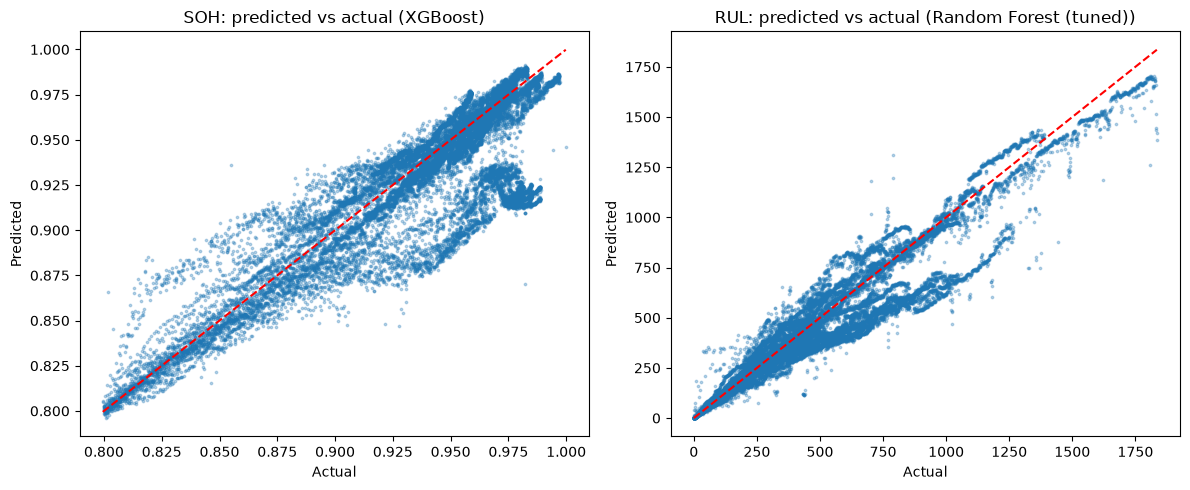

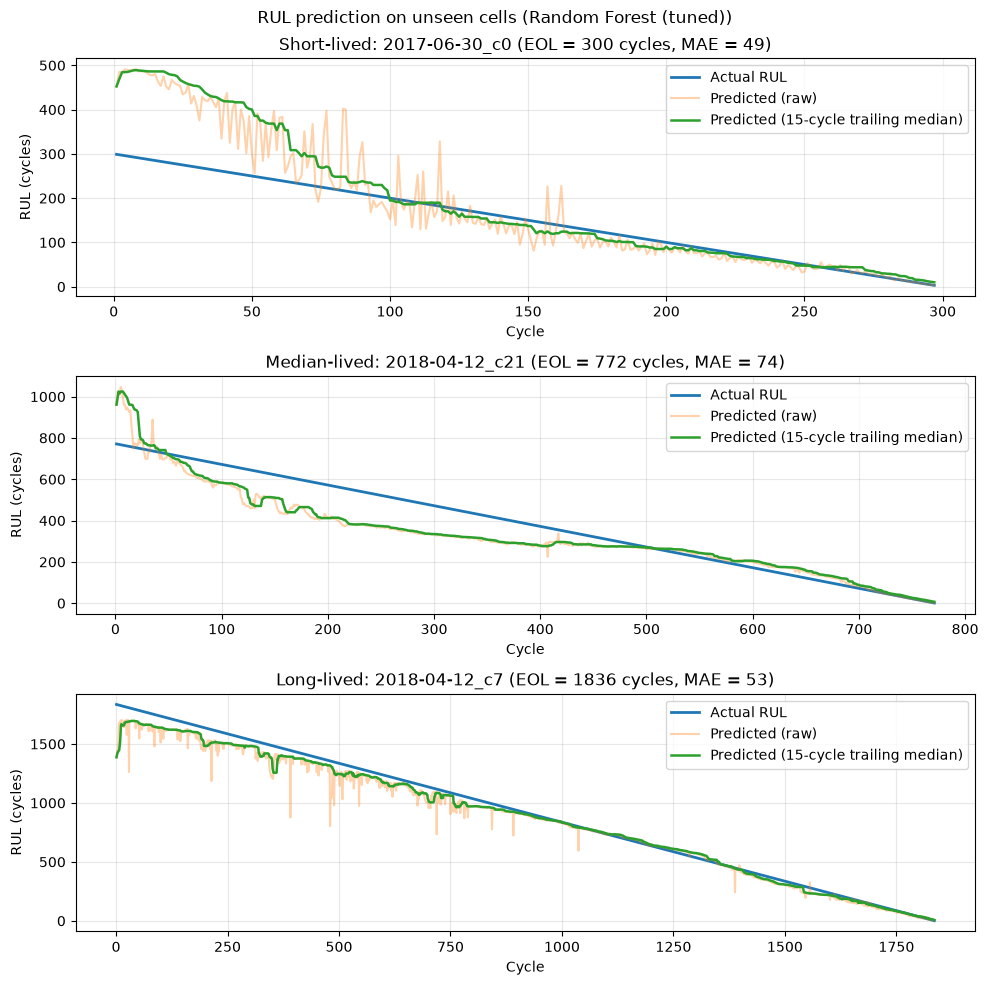

Worst 5 test cells by RUL MAE:
                EOL_cycle    MAE
cell_id                         
2018-04-12_c2      1267.0  189.3
2017-05-12_c24     1017.0  153.9
2017-05-12_c41     1051.0  138.5
2017-05-12_c40      966.0  115.6
2018-04-12_c29      858.0   88.5
Median per-cell MAE: 51.4


In [18]:
TREE_NAMES = ['Random Forest', 'XGBoost', 'XGBoost (tuned)', 'Random Forest (tuned)']

def best_tree(res, fitted):
    r = res[res['Model'].isin(TREE_NAMES)].sort_values('R2', ascending=False)
    name = r.iloc[0]['Model']
    return name, fitted[name]

soh_name, soh_model = best_tree(res_soh, fit_soh)
rul_name, rul_model = best_tree(res_rul_tuned, fit_rul_all)
print('SOH best tree model:', soh_name, '| RUL best tree model:', rul_name)

# Scatter, all test rows
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, (target, feats, name, m) in zip(ax, [('SOH', FEATS_SOH, soh_name, soh_model),
                                            ('RUL', FEATS_RUL, rul_name, rul_model)]):
    pred = m.predict(test[feats])
    a.scatter(test[target], pred, s=3, alpha=0.3)
    lo, hi = test[target].min(), test[target].max()
    a.plot([lo, hi], [lo, hi], 'r--')
    a.set(title=f'{target}: predicted vs actual ({name})', xlabel='Actual', ylabel='Predicted')
plt.tight_layout()
plt.savefig(OUT_DIR / 'scatter_pred_vs_actual.png', dpi=200, bbox_inches='tight')
plt.show()

# RUL over cycle for a short-, median- and long-lived test cell
test_eol = test.groupby('cell_id')['EOL_cycle'].first().sort_values()
chosen = [test_eol.index[0], test_eol.index[len(test_eol) // 2], test_eol.index[-1]]
tags = ['Short-lived', 'Median-lived', 'Long-lived']
fig, axes = plt.subplots(3, 1, figsize=(10, 10))
for ax_, cid, tag in zip(axes, chosen, tags):
    g = test[test['cell_id'] == cid].sort_values('cycle')
    pred = pd.Series(rul_model.predict(g[FEATS_RUL]), index=g.index)
    smooth = pred.rolling(15, min_periods=1).median()      # trailing window, display only
    mae = mean_absolute_error(g['RUL'], pred)
    ax_.plot(g['cycle'], g['RUL'], lw=2, label='Actual RUL')
    ax_.plot(g['cycle'], pred, alpha=0.35, label='Predicted (raw)')
    ax_.plot(g['cycle'], smooth, lw=1.8, label='Predicted (15-cycle trailing median)')
    ax_.set(title=f'{tag}: {cid} (EOL = {int(g["EOL_cycle"].iloc[0])} cycles, MAE = {mae:.0f})',
            xlabel='Cycle', ylabel='RUL (cycles)')
    ax_.legend(); ax_.grid(alpha=0.3)
plt.suptitle(f'RUL prediction on unseen cells ({rul_name})')
plt.tight_layout()
plt.savefig(OUT_DIR / 'rul_pred_vs_actual_cells.png', dpi=200, bbox_inches='tight')
plt.show()

# Per-cell test error (reported metrics above use the raw predictions)
err = test[['cell_id', 'EOL_cycle', 'RUL']].copy()
err['abs_err'] = np.abs(err['RUL'] - rul_model.predict(test[FEATS_RUL]))
per_cell = (err.groupby('cell_id').agg(EOL_cycle=('EOL_cycle', 'first'), MAE=('abs_err', 'mean'))
               .sort_values('MAE', ascending=False).round(1))
print('Worst 5 test cells by RUL MAE:')
print(per_cell.head(5))
print('Median per-cell MAE:', round(per_cell['MAE'].median(), 1))
per_cell.to_csv('./per_cell_rul_error.csv')

## 13. SHAP feature importance (best tree model per experiment)

SOH (XGBoost): max |prediction - (base + sum SHAP)| = 7.75e-07


C:\Users\DELL\AppData\Local\Temp\ipykernel_12272\773027076.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xs, show=False)


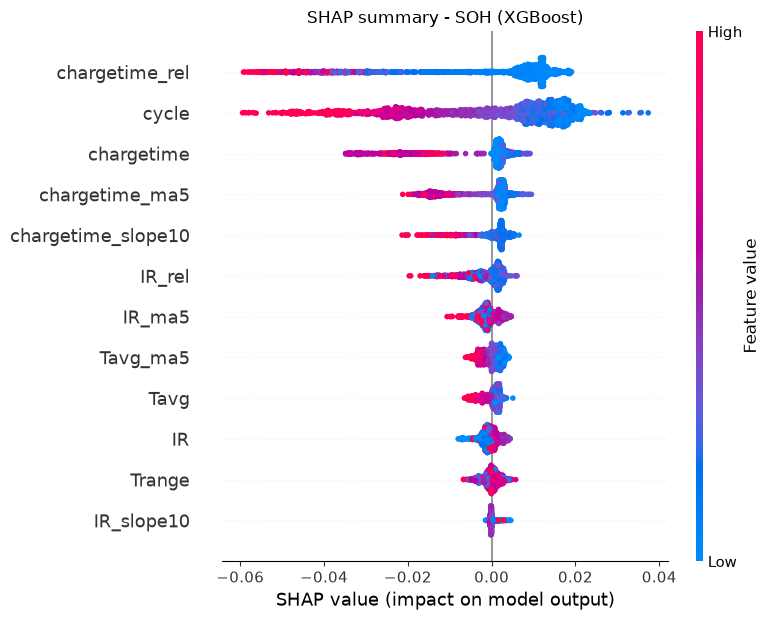

C:\Users\DELL\AppData\Local\Temp\ipykernel_12272\773027076.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xs, plot_type='bar', show=False)


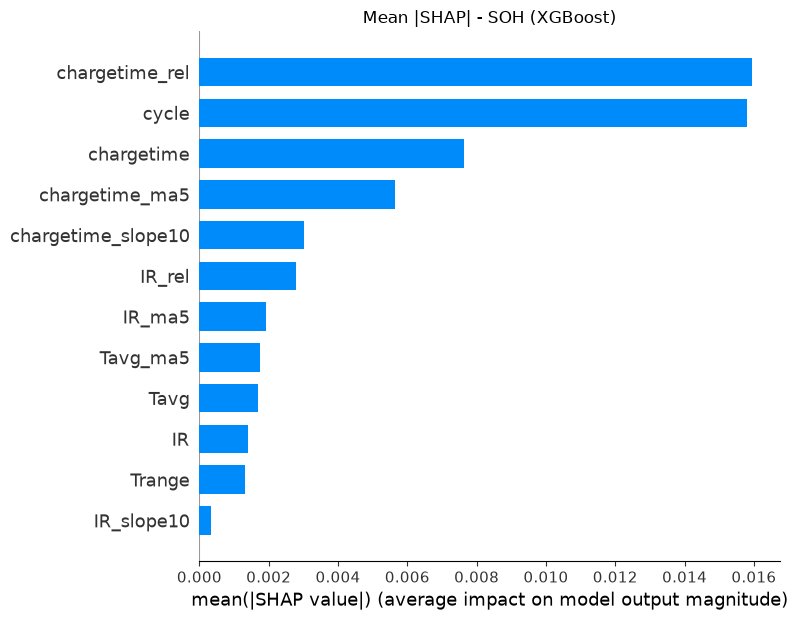

RUL (Random Forest (tuned)): max |prediction - (base + sum SHAP)| = 2.27e-11


C:\Users\DELL\AppData\Local\Temp\ipykernel_12272\773027076.py:15: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xs, show=False)


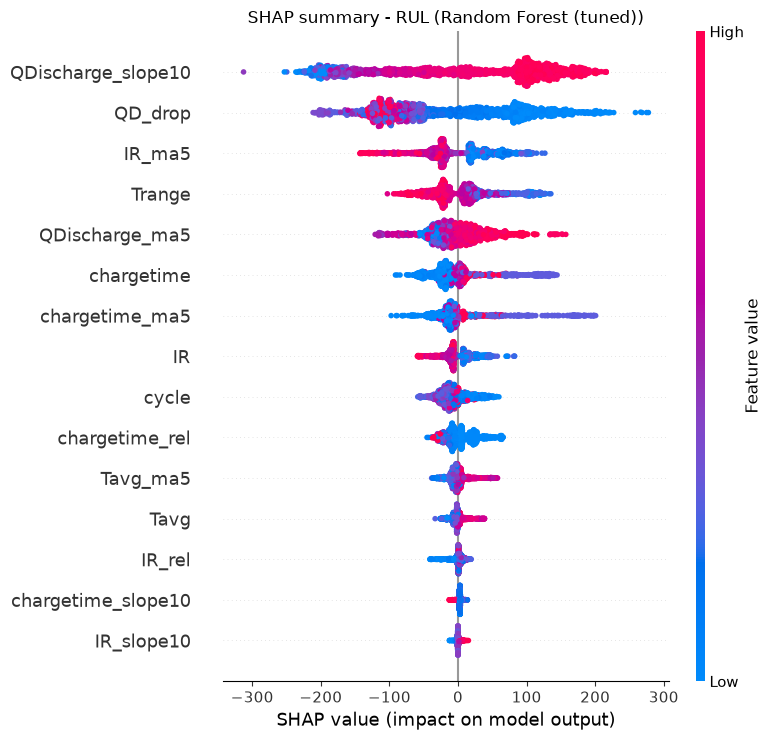

C:\Users\DELL\AppData\Local\Temp\ipykernel_12272\773027076.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, Xs, plot_type='bar', show=False)


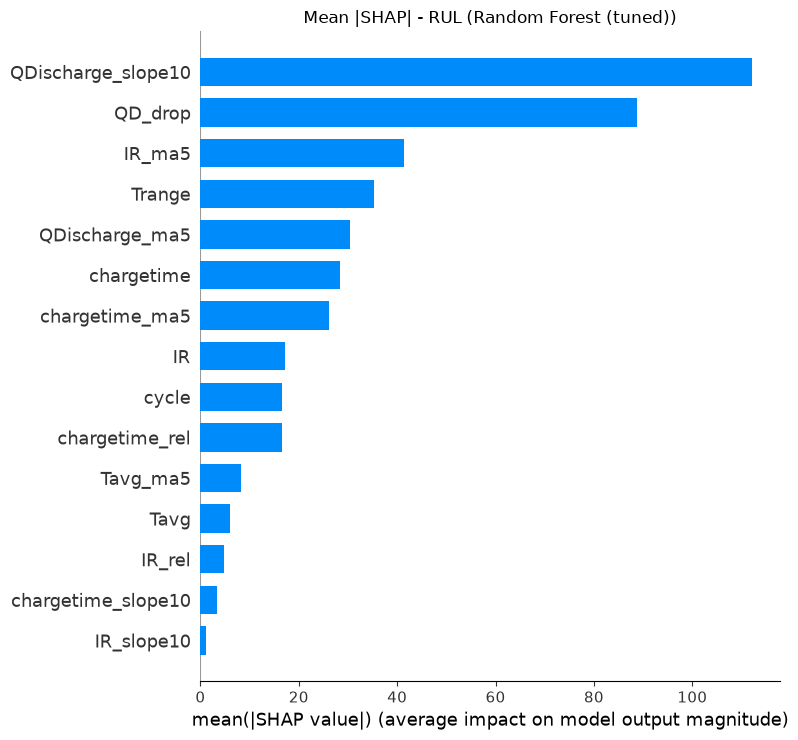

chargetime_rel        0.0160
cycle                 0.0158
chargetime            0.0076
chargetime_ma5        0.0056
chargetime_slope10    0.0030
IR_rel                0.0028
Name: mean |SHAP|, dtype: float32 

QDischarge_slope10    112.2136
QD_drop                88.7108
IR_ma5                 41.3140
Trange                 35.3113
QDischarge_ma5         30.4911
chargetime             28.4314
Name: mean |SHAP|, dtype: float64


In [19]:
import shap

def shap_report(target, feats, name, m, n=2000):
    Xs = test[feats].sample(min(n, len(test)), random_state=SEED)
    ex = shap.TreeExplainer(m)
    sv = ex.shap_values(Xs)
    if isinstance(sv, list):
        sv = sv[0]
    assert sv.shape == (len(Xs), len(feats)), f'unexpected SHAP shape {sv.shape}'
    base = np.ravel(ex.expected_value)[0]
    print(f'{target} ({name}): max |prediction - (base + sum SHAP)| = '
          f'{np.abs(m.predict(Xs) - (base + sv.sum(axis=1))).max():.2e}')

    plt.figure()
    shap.summary_plot(sv, Xs, show=False)
    plt.title(f'SHAP summary - {target} ({name})')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'shap_summary_{target.lower()}.png', dpi=200, bbox_inches='tight')
    plt.show()

    plt.figure()
    shap.summary_plot(sv, Xs, plot_type='bar', show=False)
    plt.title(f'Mean |SHAP| - {target} ({name})')
    plt.tight_layout()
    plt.savefig(OUT_DIR / f'shap_bar_{target.lower()}.png', dpi=200, bbox_inches='tight')
    plt.show()

    imp = pd.Series(np.abs(sv).mean(axis=0), index=feats).sort_values(ascending=False)
    return imp.round(4).rename('mean |SHAP|')

imp_soh = shap_report('SOH', FEATS_SOH, soh_name, soh_model)
imp_rul = shap_report('RUL', FEATS_RUL, rul_name, rul_model)
print(imp_soh.head(6), '\n')
print(imp_rul.head(6))

## 14. Optional: 5-fold grouped cross-validation (more robust than one split)
Set `RUN_CV = True` to run it. It takes a few minutes. Reports mean and standard deviation across folds for the RUL experiment.

In [21]:
RUN_CV = True

if RUN_CV:
    gkf = GroupKFold(n_splits=5)
    rows = []
    for fold, (tr, te) in enumerate(gkf.split(df, groups=df['cell_id'])):
        X_tr, y_tr = df.iloc[tr][FEATS_RUL], df.iloc[tr]['RUL']
        X_te, y_te = df.iloc[te][FEATS_RUL], df.iloc[te]['RUL']
        for name, proto in models.items():
            _, p = fit_predict(proto, name, X_tr, y_tr, X_te)
            rows.append({'Fold': fold, 'Model': name, **scores(y_te, p)})
        print('fold', fold, 'done')
    cv = pd.DataFrame(rows)
    cv_summary = cv.groupby('Model')[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).round(3)
    cv_summary.to_csv('./cv_summary_rul.csv')
    display(cv_summary)
else:
    print('Skipped (set RUN_CV = True to run).')

fold 0 done
fold 1 done
fold 2 done
fold 3 done
fold 4 done


MAE             RMSE             R2       
                      mean     std     mean     std   mean    std
Model                                                            
Linear Regression  153.658  11.767  212.451  31.343  0.598  0.102
Random Forest       91.110  20.488  160.843  42.298  0.757  0.121
SVR                108.997  23.260  184.902  56.053  0.674  0.179
XGBoost             90.189  14.890  157.029  35.123  0.773  0.095

## 15. Notes for the report
- Cells kept and excluded, with reasons, are printed in Section 3 (2 cells had no label, 10 stopped before 80% capacity, glitch rows were removed).
- The train/test split is by cell, with an assert that no cell appears in both sets.
- Only XGBoost was hyperparameter-tuned; the other models use default settings.
- SVR was trained on a 15,000-row random subsample for speed.
- Results use a single 26-cell test split, so scores carry some sampling noise (see the optional CV in Section 14).
- Early-life reference features use each cell's first 5 recorded cycles (minor look-ahead for cycles 2-5).
- Charge-time glitches were filtered with `CHARGETIME_MAX`; this is stated in Section 3.
- The ablation (Section 9) shows how much capacity-trend information contributes to RUL prediction.
- Charge time can partly encode a cell's fast-charging protocol rather than its degradation; discuss this when interpreting SHAP.